# AM6020 Project - SVM on Wine Quality
Classification of red and white wines from the [UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine+quality) using Support Vector Machines.

## How to run this notebook

### 1. Create the environment (only once, in a terminal opened in the project folder)
```bash
python -m venv .venv

# Activate it
.venv\Scripts\Activate.ps1     # Windows (PowerShell)
source .venv/bin/activate      # macOS / Linux

pip install -r requirements.txt
```
With conda: `conda create -n am6020 python` then `conda activate am6020` and `pip install -r requirements.txt`.

`requirements.txt` includes `ipykernel`, which is needed to use the environment as a Jupyter kernel.

### 2. Select the kernel
- **VS Code**: click on *Select Kernel* (top right) → *Python Environments* → `.venv`.
- **Jupyter**: *Kernel* → *Change Kernel* → the environment created above.

### 3. Run the notebook
- Run the cells **in order from the top** (*Run All* in VS Code / Jupyter).
- The notebook must be opened from the project folder: all the data paths (`data/`, `output/`) are relative to it.
- The **first run needs an internet connection**, to download the datasets.
- The next cell checks the environment and installs the missing librairies automatically, so steps 1 and 2 are the only manual ones.

In [33]:
# Check the environment and install the needed librairies (listed in `requirements.txt`) if necessary
import os
import sys

print(f"Python {sys.version.split()[0]} ({sys.executable})")

# Warn if the kernel is not running in a virtual environment (venv or conda)
if sys.prefix == sys.base_prefix and "CONDA_DEFAULT_ENV" not in os.environ:
    print("Warning: this kernel is not running in a virtual environment, the librairies will be installed globally.")

# The data paths are relative to the project folder, so the notebook must be run from it
if os.path.exists("requirements.txt"):
    %pip install -r requirements.txt --quiet
else:
    print("'requirements.txt' not found: installing the default librairies instead.")
    %pip install ipykernel numpy scikit-learn matplotlib pandas seaborn --quiet

# %pip install ucimlrepo # not mandatory, but can be useful to download datasets from the UCI repository through a simple command

Python 3.14.4 (c:\Users\alex\Documents\Ecole\Efrei-UCC 2026-2027\UCC\AM6020\Project\.venv\Scripts\python.exe)
Note: you may need to restart the kernel to use updated packages.


In [34]:
# Basic imports
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
#import ucimlrepo


# Scikit-learn imports
"""TODO: Add the necessary imports from scikit-learn here.""" 
# For example: 
# from sklearn.model_selection import train_test_split
# from sklearn.svm import SVC
# from sklearn.metrics import accuracy_score


# Librairies configuration
%matplotlib inline
%config InlineBackend.figure_format = 'retina'  # 'retina' = high resolution ; 'png' = low resolution ; 'svg' = vectorial format (high quality, but heavy files)
plt.rcParams["figure.dpi"] = 150                # resolution of the figures
plt.rcParams["font.size"] = 11                  # global font size for the figures

### Data setup
This cell prepares everything the rest of the notebook needs. **It must be run at least once, on the first execution of the notebook.** After that, running it again is safe: it only creates or changes what is missing or not consistent.

If needed, it will:
- create the `data/` and `output/` directories;
- download the red and white wine datasets from the UCI Machine Learning Repository into `data/winequality-red.csv` and `data/winequality-white.csv`;
- harmonize the format of the datasets (`;` separator, column names with `_` instead of spaces, e.g. `fixed_acidity`);
- fuse both datasets into `data/winequality-red+white.csv`, with an extra `type` column (`red` / `white`).

In [35]:
# Create the `data/` and `output/` directories if they don't exist
if not os.path.exists("data"):
    os.makedirs("data")
    print("'Data/' directory created.")

if not os.path.exists("output"):
    os.makedirs("output")
    print("'Outputs/' directory created.")

# Download the red and white wine datasets from the UCI Machine Learning Repository if they don't already exist
if not os.path.exists("data/winequality-red.csv") or not os.path.exists("data/winequality-white.csv"):
    red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
    
    red_wine_data = pd.read_csv(red_wine_url, sep=';')
    white_wine_data = pd.read_csv(white_wine_url, sep=';')
    
    red_wine_data.to_csv("data/winequality-red.csv", sep=";", index=False)
    white_wine_data.to_csv("data/winequality-white.csv", sep=";", index=False)
    
    print("Wine datasets downloaded and saved to 'data' directory.")


# Harmonize the format of the wine datasets (separator and column names)
# This step is always run, so that the files stay consistent even if they are downloaded or created again
# It is cheap (a few thousand lines) and a file is only rewritten if something needs to be changed
# It must run before the fusion, otherwise a source file with a wrong separator would corrupt the fused dataset
def harmonize_wine_datasets(paths = ("data/winequality-red.csv",
                                     "data/winequality-white.csv",
                                     "data/winequality-red+white.csv")):

    for path in paths:
        # Skip the files that don't exist yet (e.g. the fused dataset on the first run)
        if not os.path.exists(path):
            continue

        # Detect the separator from the header line (";" expected, "," otherwise)
        with open(path, encoding="utf-8") as f:
            header = f.readline()
        sep = ";" if ";" in header else ","

        data = pd.read_csv(path, sep=sep)

        # Column names: remove surrounding spaces and replace inner spaces by "_" (e.g. "fixed acidity" -> "fixed_acidity")
        clean_columns = data.columns.str.strip().str.replace(" ", "_")

        if sep != ";" or list(clean_columns) != list(data.columns):
            data.columns = clean_columns
            data.to_csv(path, sep=";", index=False)
            print(f"'{path}' harmonized.")

harmonize_wine_datasets()


# Fuse the red and white wine datasets into a single dataset if it doesn't already exist
# We created a dedicated function for this task, so that it can be reused later if needed  
# Default parameters are set to the paths of the red and white wine datasets and the output path for the fused dataset
def fuse_wine_datasets(red_wine_path = "data/winequality-red.csv", 
                       white_wine_path = "data/winequality-white.csv", 
                       output_path = "data/winequality-red+white.csv"):
    
    red_wine = pd.read_csv(red_wine_path, sep=";")
    white_wine = pd.read_csv(white_wine_path, sep=";")

    # Add a new column to indicate the type of wine with boolean values (0 for red, 1 for white)
    red_wine["is_white"] = 0
    white_wine["is_white"] = 1

    # Add a new column to indicate the type of wine with string values ("red" or "white")
    red_wine["type"] = "red"
    white_wine["type"] = "white"

    # Concatenate the two datasets and save the result to a new CSV file
    wine_data = pd.concat([red_wine, white_wine], ignore_index=True)
    wine_data.to_csv(output_path, sep=";", index=False)

    print(f"File created with {len(wine_data)} lines.")

if not os.path.exists("data/winequality-red+white.csv"):
    fuse_wine_datasets()

In [36]:
#fuse_wine_datasets()  # Run it again to ensure the file is up-to-date and consistent with the source files

# This cell must be run each time the kernel is started or reloaded

In [37]:
# Define the datasets and their sizes for later use in the notebook
red_wine_data = pd.read_csv("data/winequality-red.csv", sep=";")
red_wine_size = len(red_wine_data)

white_wine_data = pd.read_csv("data/winequality-white.csv", sep=";")
white_wine_size = len(white_wine_data)

fused_wine_data = pd.read_csv("data/winequality-red+white.csv", sep=";")
fused_wine_size = len(fused_wine_data)


# Define the datasets and their attributes (dataframe, color) for easy access
datasets = {
    "Red Wine": (red_wine_data, "#800020"),       # Rouge bordeaux / Maroon
    "White Wine": (white_wine_data, "#D4AC0D"),    # Jaune doré (plus visible sur fond blanc)
    "Red + White Wine": (fused_wine_data, "#6C3483") # Violet
}



In [38]:
for name, (data, color) in datasets.items():
    print(f"{name}")
    print(f"Samples number: {len(data)}")
    print("Columns :", ", ".join(data.columns))
    print(f"Color for plots: {color}")

    print()


Red Wine
Samples number: 1599
Columns : fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, pH, sulphates, alcohol, quality
Color for plots: #800020

White Wine
Samples number: 4898
Columns : fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, pH, sulphates, alcohol, quality
Color for plots: #D4AC0D

Red + White Wine
Samples number: 6497
Columns : fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, pH, sulphates, alcohol, quality, is_white, type
Color for plots: #6C3483



# Matplotlib plotting

## Plots I recommend
* Correlation heatmap: an overview of all columns in a single image. It is often the best starting point.
* Boxplots by quality, using small multiples: one panel for each key variable (alcohol, volatile acidity, sulfates, density, etc.), with quality on the x-axis. They directly show which variables influence quality.
* Red vs. white distributions (KDE or overlaid histograms) for a few variables. This shows how the two datasets differ.
* Scatter plots using color and size, focusing on the two or three pairs of variables most strongly correlated with quality.
* Pairplot with only 4 or 5 variables: with all 12 columns, it becomes unreadable.
* 2D PCA at the end, colored by quality or wine type, as a summary. It provides a useful overview, but is not necessary to understand the data.

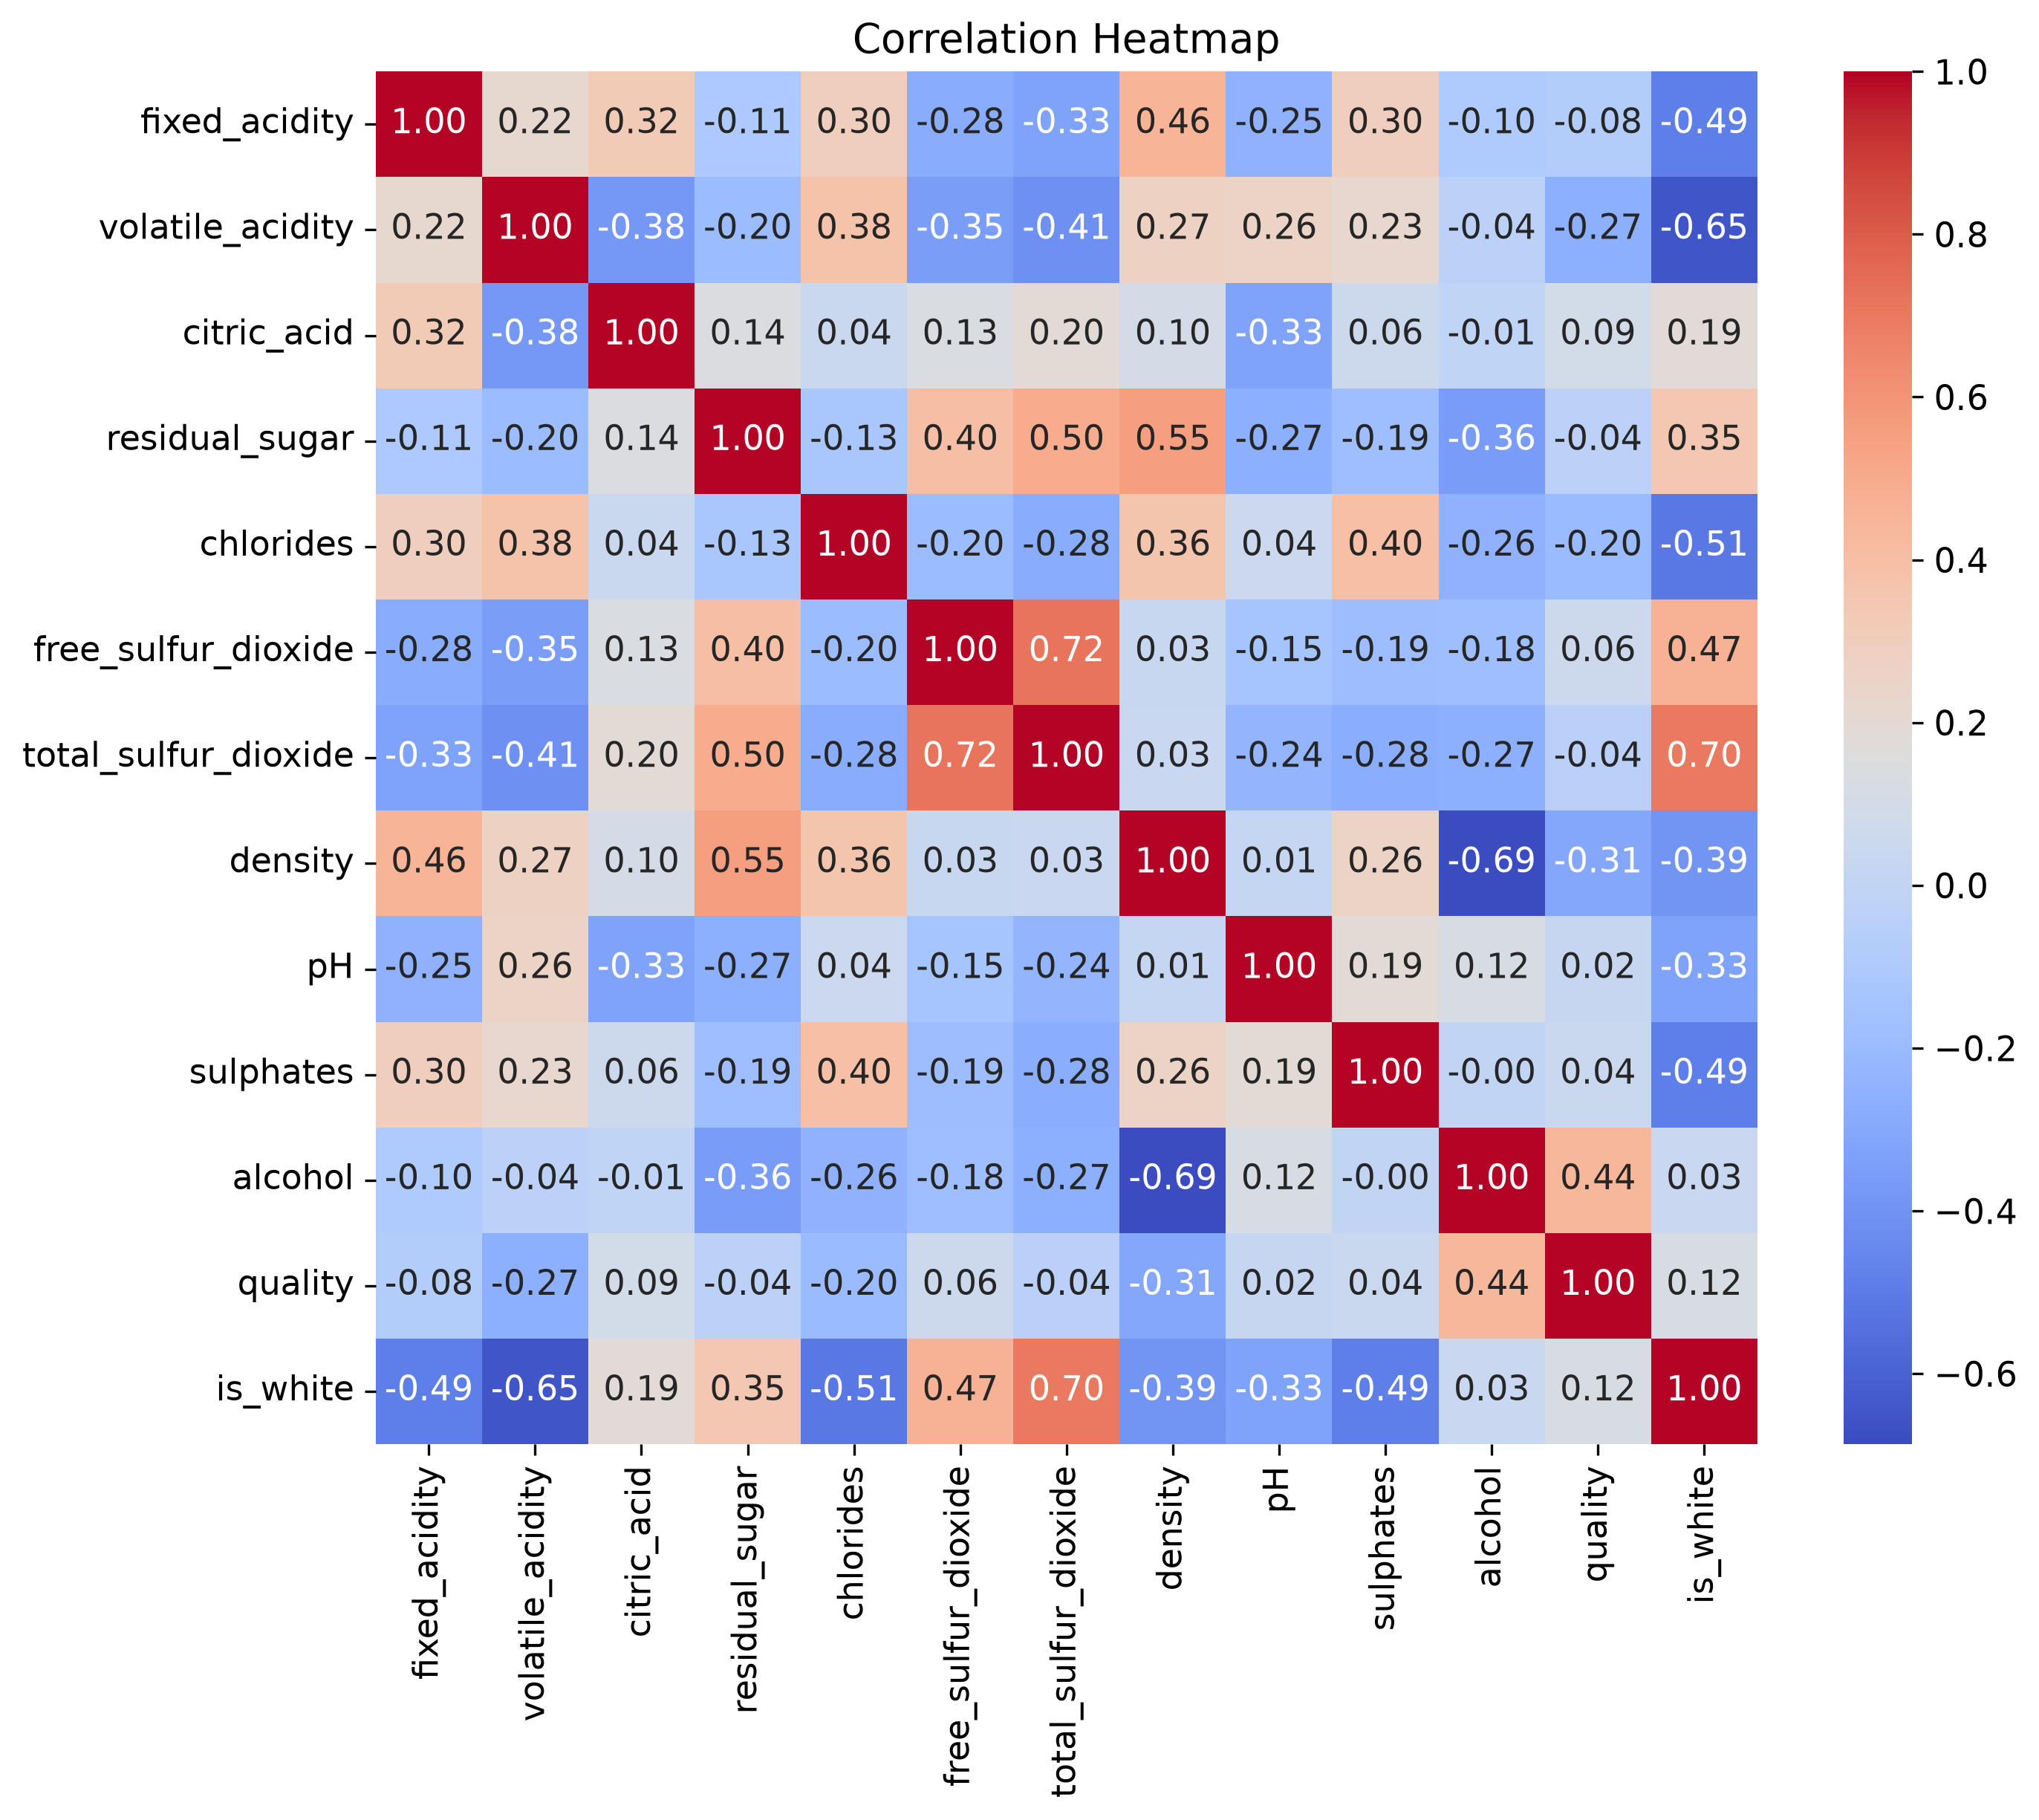

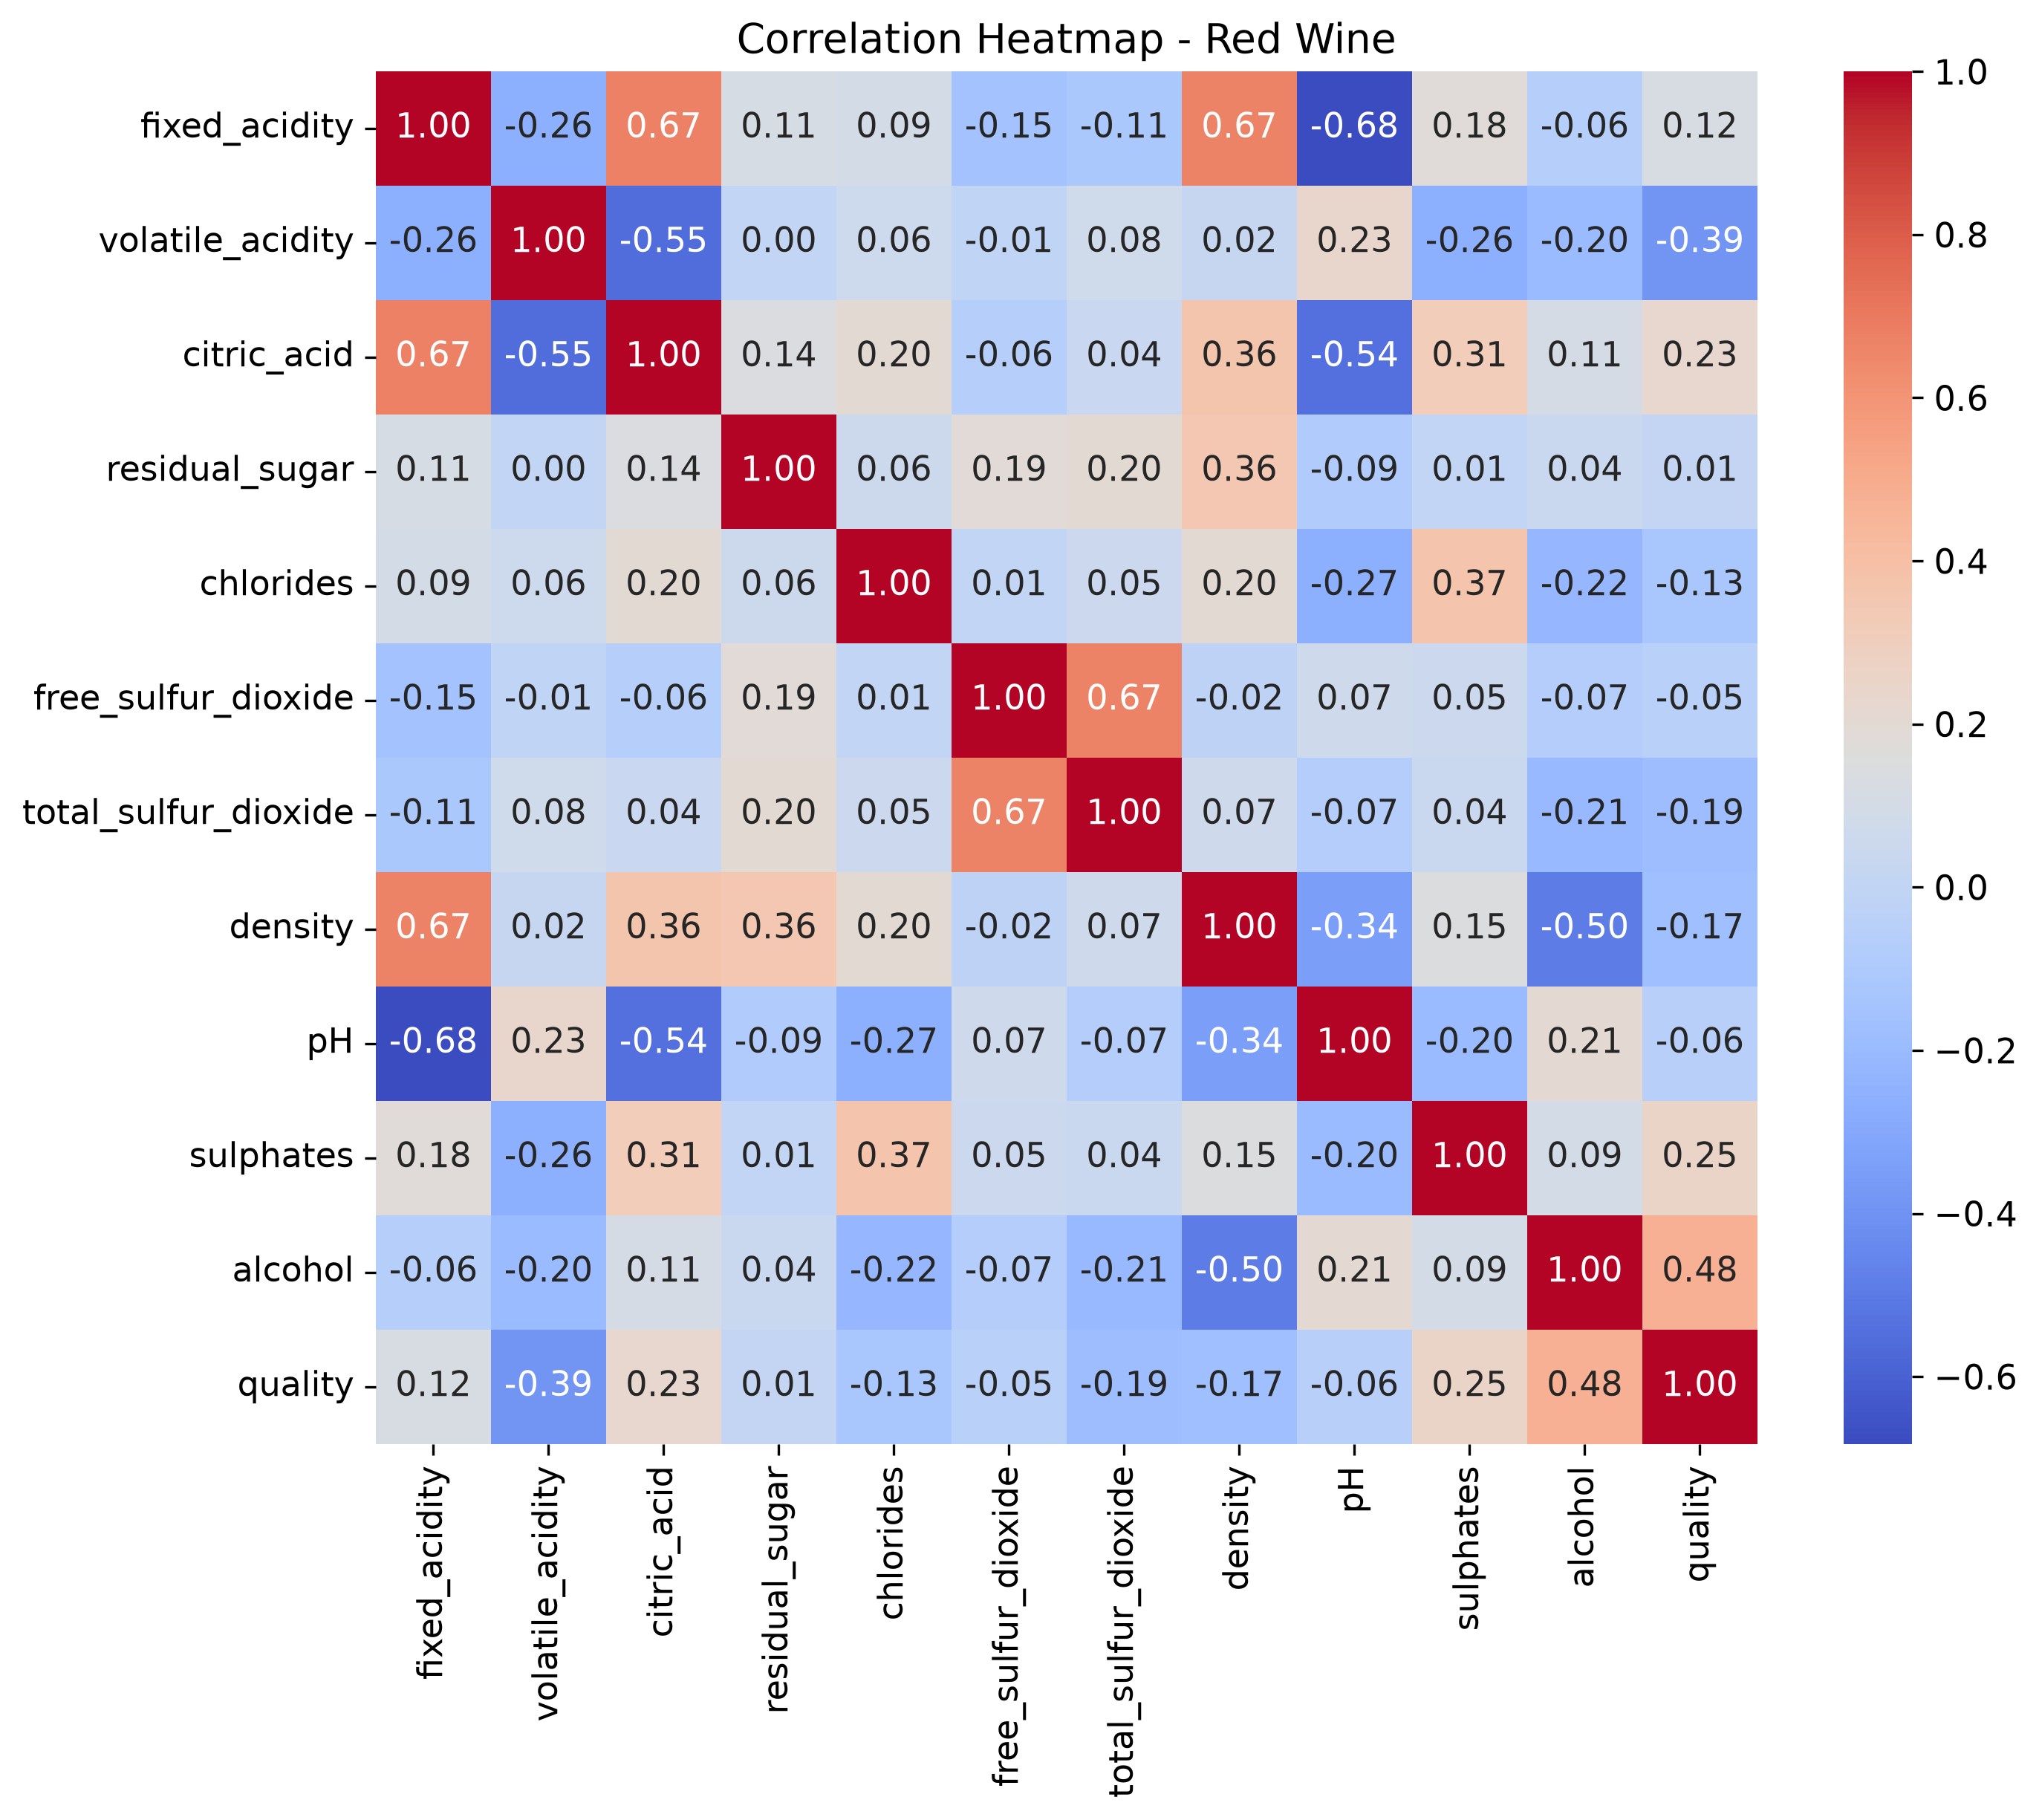

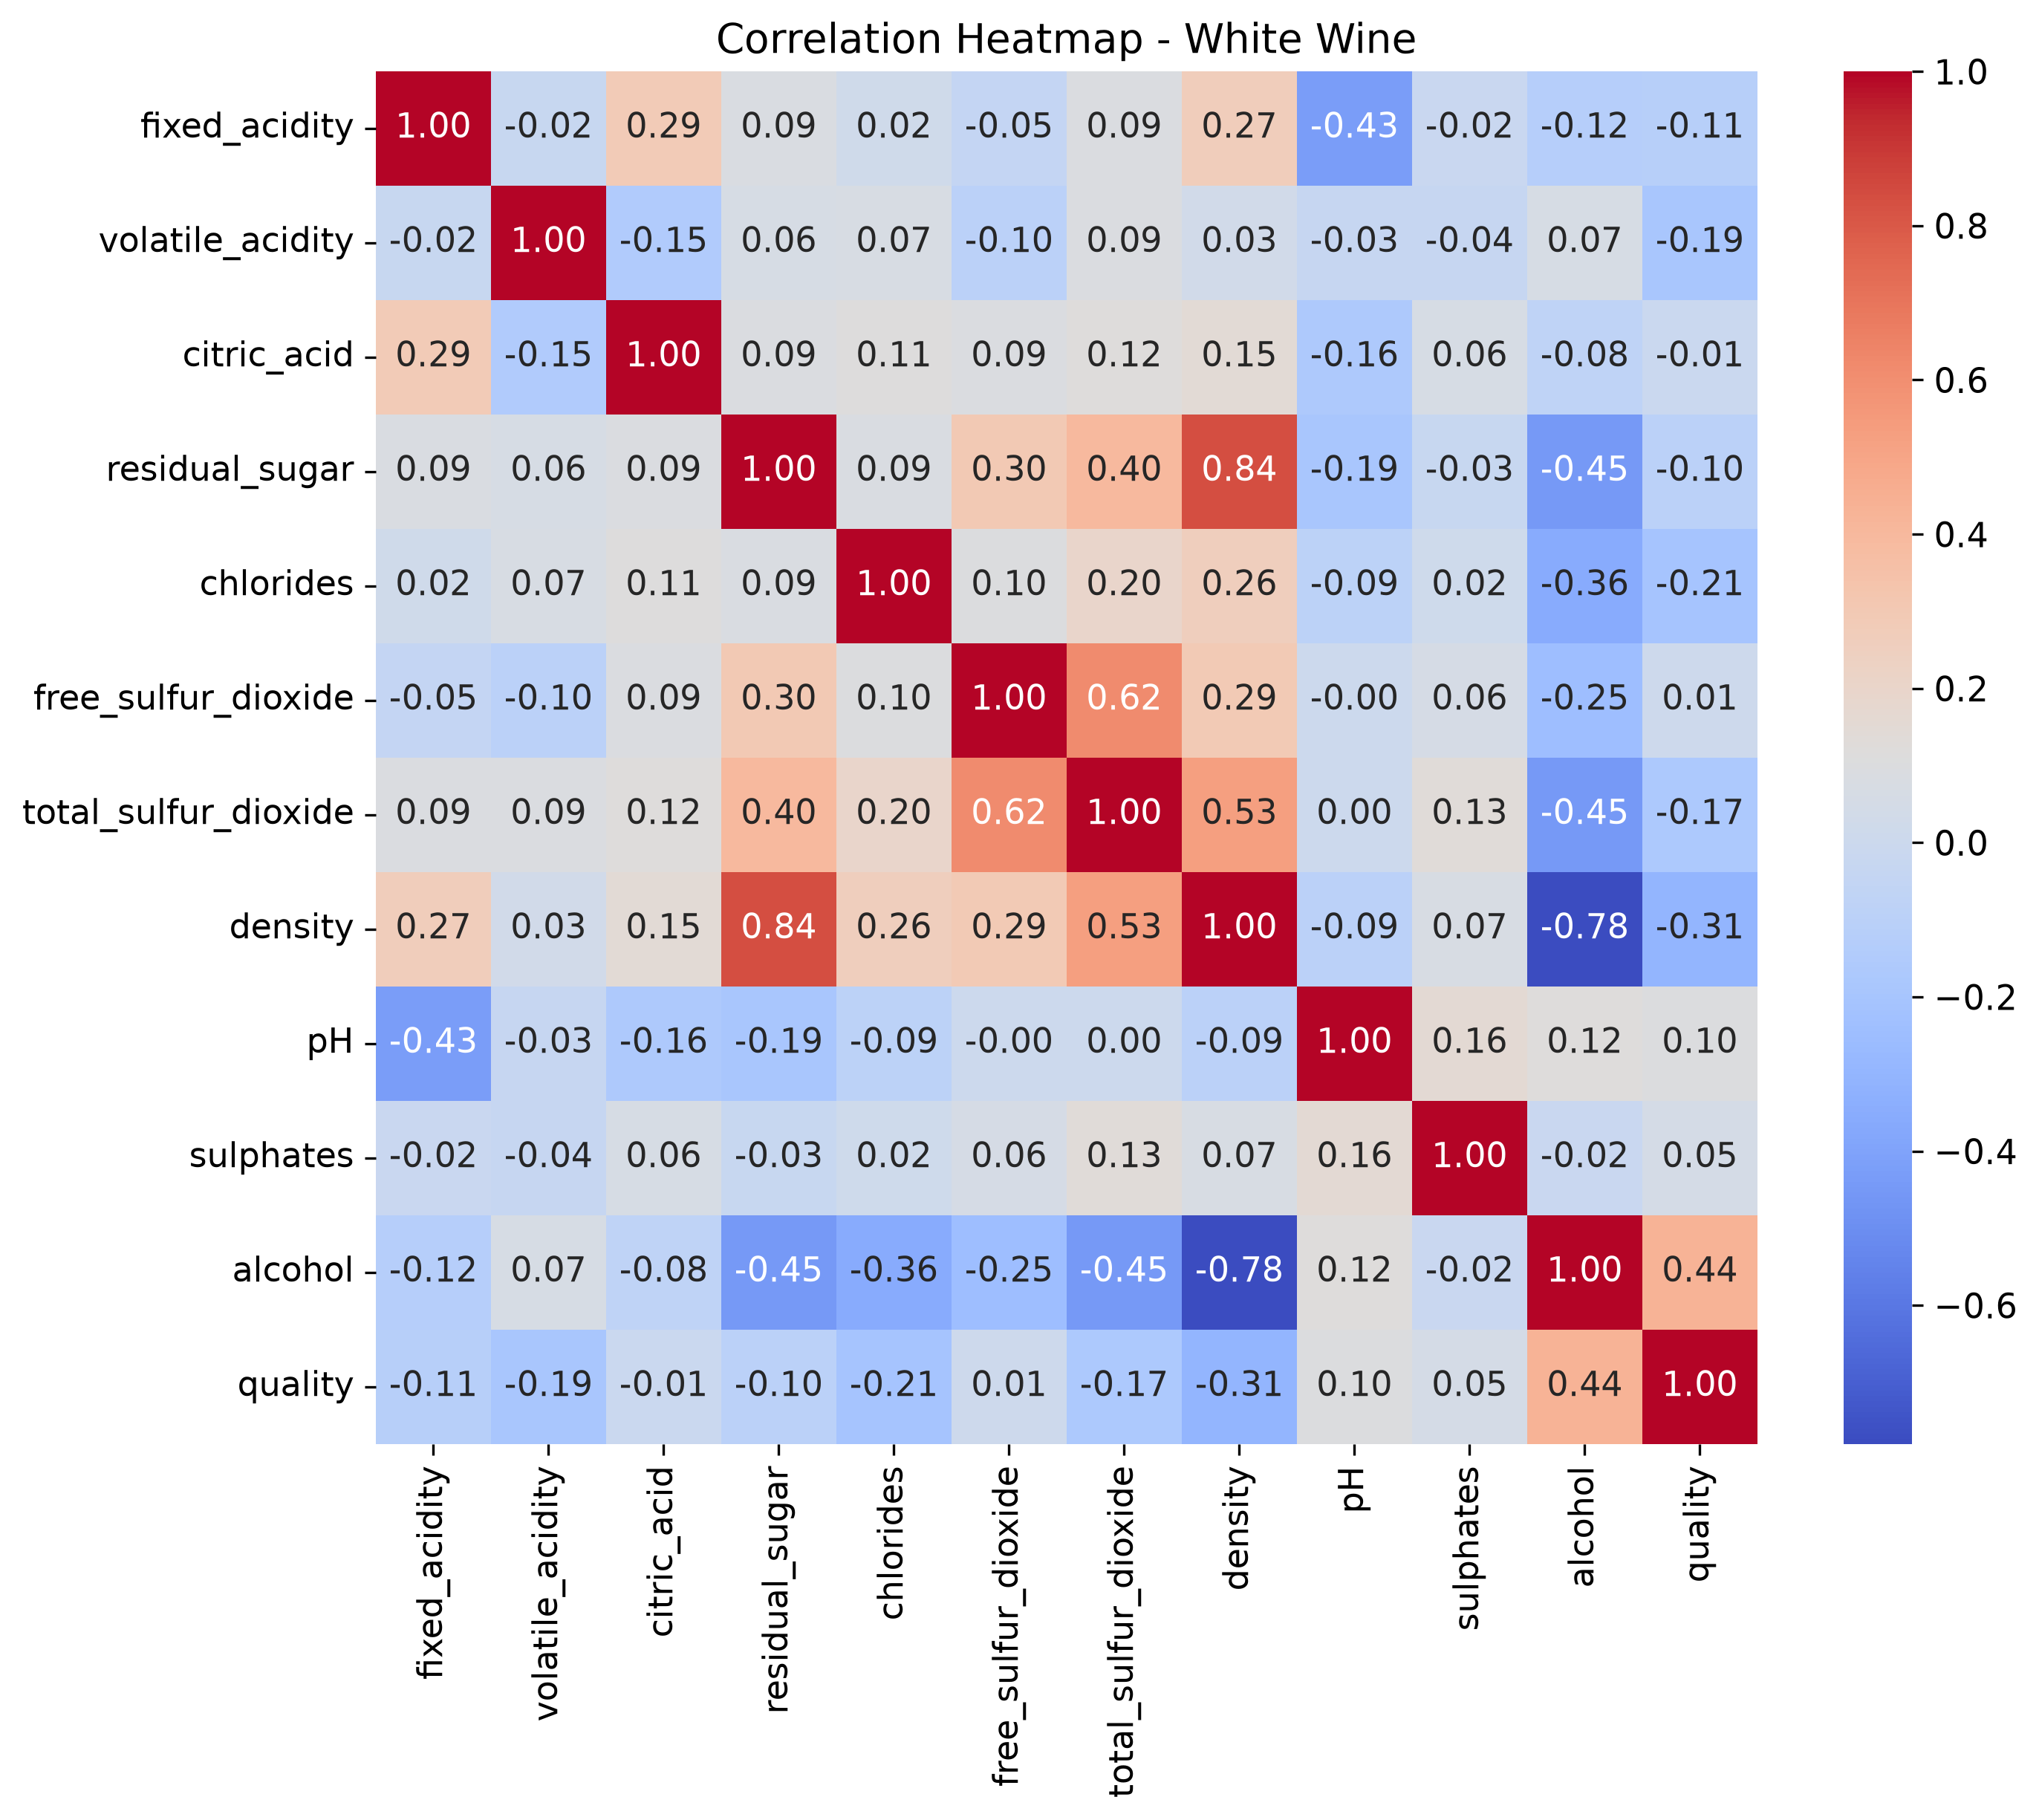

In [46]:
# Function to plot the correlation heatmap of a dataset
def plot_correlation_heatmap(dataset = fused_wine_data, title = "Correlation Heatmap", figsize = (10, 8), cmap = "coolwarm"):
    """
    Plots a correlation heatmap for the given dataset.

    Parameters:
    - dataset: pandas DataFrame containing the data. By default, it uses the fused wine dataset.
    - title: Title of the heatmap. By default, it is set to "Correlation Heatmap".
    - figsize: Size of the figure. By default, it is set to (10, 8).
    - cmap: Colormap to use for the heatmap. By default, it is set to "coolwarm".
    """
    plt.figure(figsize=figsize)
    numeric_dataset = dataset.select_dtypes(include="number") # Select only numeric columns for correlation calculation because correlation is not defined for non-numeric data
    correlation_matrix = numeric_dataset.corr()
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap=cmap, cbar=True)
    plt.title(title)
    plt.show()

plot_correlation_heatmap()
plot_correlation_heatmap(red_wine_data, title="Correlation Heatmap - Red Wine")
plot_correlation_heatmap(white_wine_data, title="Correlation Heatmap - White Wine")

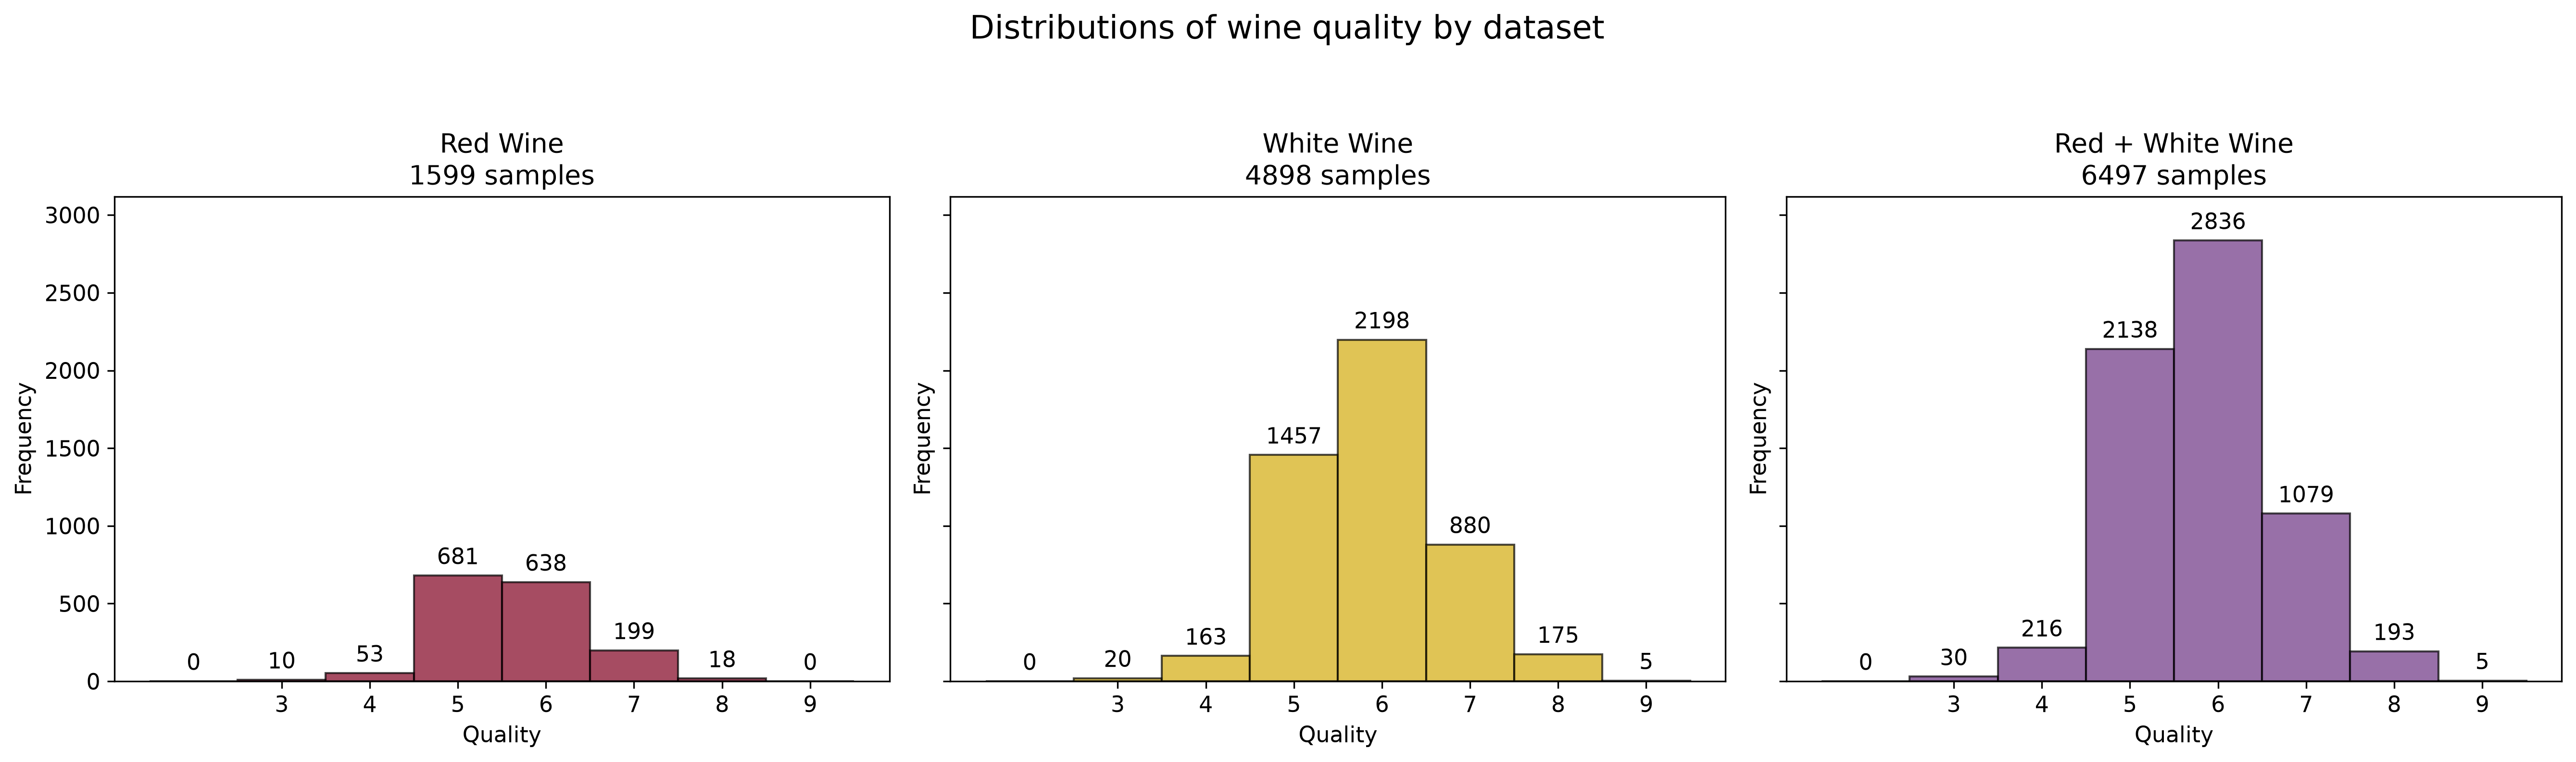

In [40]:
fig, axes = plt.subplots(1, len(datasets), figsize=(18, 5), sharey=True)

for ax, (name, (data, color)) in zip(axes, datasets.items()):
    _, _, bars = ax.hist(
        data["quality"],
        bins=np.arange(1.5, 10.5, 1),
        alpha=0.7,
        edgecolor="black",
        color=color
    )

    ax.bar_label(bars, fmt="%d", padding=3)     # shows the number above each bar
    ax.margins(y=0.1)                           # leaves space above the highest bar

    ax.set_xlabel("Quality")
    ax.set_ylabel("Frequency")
    ax.set_title(f"{name}\n{len(data)} samples")
    ax.set_xticks(range(3, 10))

fig.suptitle("Distributions of wine quality by dataset", fontsize=16, y=1.05)

plt.tight_layout()
plt.show()

# Save the figure
#fig.savefig("output/quality_distributions_hist.png", dpi=600, bbox_inches="tight")


In [41]:
print("Done")

Done
